**Innovation Management · A.Y. 2026/27 · Politecnico di Torino** · Tutorial 2, notebook 1

| | |
|---|---|
| **Goal** | Access the full text of European patent publications on TIP: what EP full-text and EPAB are, what is inside, the parts of the patent text, the search report, and how to query and download all of them. |
| **Before this** | Tutorial 1 (patent attributes, competitive landscape) |
| **Time** | 45 min |
| **EPAB environment** | TEST (switch to PROD for final numbers) |

← [Tutorial 1 · Step 2 of the PW: competitive landscape](../tutorial_1/11_competitive_landscape.ipynb) &nbsp;|&nbsp; [Back to the README](../README.md)

<sub>Adapted from the EPO TIP training materials (https://github.com/epo/tip-training). This version has been modified and is not authorised by the EPO; the EPO is not responsible for its correctness.</sub>

# The full text of EP publications: EP full-text and EPAB

PATSTAT gives us bibliographic data: numbers, dates, classes, applicants. It contains titles and abstracts, but not the **claims** and the **description**, and not the **search report**. These are in **EP full-text**.

**What EP full-text is.** It gives access to the full text of the entire collection of **EP publications (A and B)**. The EPO has a legal obligation to publish the patent applications it receives (**EP-A documents**) and the patents it grants (**EP-B documents**). The EPO publishes them every week: more than 7 million publications since 1978.

EP full-text also includes the **Euro-PCT applications published by WIPO and not republished by the EPO**, i.e. international applications filed in English, French or German, in the form of full text (descriptions and claims) and scanned pages of the international publications:

- **Full text:** the international publications present in the database were published by WIPO as of **2019 week 1**; international publications published before 2019 week 1 will be included progressively.

**What EPAB is.** **EPAB** (EP **A** and **B** publications) is the implementation of EP full-text in TIP: a Python library, pre-installed in your TIP workspace, with a **client** (`EPABClient`) that queries the database and returns the publications as DataFrames, lists or widgets.

| | PATSTAT | EPAB |
|---|---|---|
| One row is | an application (TLS201), a person, a CPC symbol… | a **publication** (one application has several: A1, B1…) |
| Coverage | worldwide, about 100 offices | **EPO only** (plus Euro-PCT published by WIPO) |
| Text | title and abstract | title, abstract, **claims**, **description**, **search report** |
| Languages | mostly English + some national languages| the three EPO languages: **English, German, French** |

**Kind codes of EP publications** (the field `publication.kind`):

| Kind | Publication |
|---|---|
| A1 | application published **with** the European search report |
| A2 | application published **without** the search report (it was not ready at 18 months) |
| A3 | search report published later, on its own |
| A4 | supplementary search report (for Euro-PCT applications) |
| A8, A9 | corrected A publications |
| B1 | granted patent |
| B2 | patent maintained in amended form after opposition |
| B3 | patent after a limitation procedure |
| B8, B9 | corrected B publications |

## Contents

1. Setup: the EPAB client
2. What is inside EPAB: the fields, and one whole publication
3. Queries and results
4. The parts of the patent text, and how to access them
5. The search report: what it is, what is inside, and how to access it
6. Large queries: statistics, batches, browsing
7. SQL queries

## 1. Setup: the EPAB client

All imports in one cell. When you create the client with `env="TEST"` you work on a **test database** of about 10 thousand publications: queries are fast while you write your code. When you are ready for the real analysis, switch to `env="PROD"`, the full database of more than 7 million publications.

In [1]:
import re
from pprint import pprint

import pandas as pd

from epo.tipdata.epab import EPABClient

ENV = "TEST"                     # "TEST" while developing, "PROD" for the real analysis

# the client: every query starts from this object
epab = EPABClient(env=ENV)

pd.set_option("display.max_colwidth", 120)

## 2. What is inside EPAB

### 2.1 The fields

Each publication has many fields, organised in levels: `application.number` and `application.filing_date` are nested in the **super field** `application`. The method `fields()` shows them in a widget, with a description of each field:

In [2]:
epab.fields()

WidDatabaseFields(header='', input_data={'': [{'name': 'epab_doc_id', 'type': 'STRING', 'mode': 'REQUIRED', 'd…

For example, the super field `publication`:

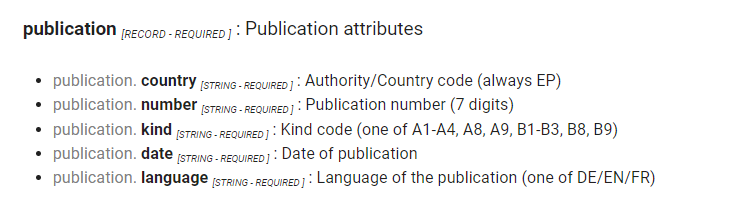

The widget is good for browsing. To **print the whole list** as a table we ask the database itself: EPAB is a single table on Google BigQuery, and BigQuery describes every column, nested fields included, in its `INFORMATION_SCHEMA`.

In [3]:
# ---------------------------------------------------------------- the list of all fields (schema)
# EPAB is one table on BigQuery: project.dataset.table
project, dataset, table = epab.full_table_name.split(".")

# BigQuery describes every column of the table, nested fields included
schema_sql = f"""
    SELECT field_path, data_type, description
    FROM `{project}.{dataset}.INFORMATION_SCHEMA.COLUMN_FIELD_PATHS`
    WHERE table_name = '{table}'
"""


def fields_from_widget(fields, prefix=""):
    "Fallback: walk the field tree shown by epab.fields()."
    rows = []
    for f in fields:
        path = prefix + f["name"]
        rows.append({"field_path": path, "data_type": f.get("type"), "description": f.get("description")})
        rows += fields_from_widget(f.get("fields", []), path + ".")
    return rows


try:
    schema = pd.DataFrame(epab.sql_query(schema_sql))
except Exception:                                    # no access to INFORMATION_SCHEMA: read the widget instead
    schema = pd.DataFrame(fields_from_widget(epab.fields().input_data[""]))

# ---------------------------------------------------------------- print it, super field by super field
# the super field each field belongs to (the part before the first dot)
schema["super field"] = schema["field_path"].str.split(".").str[0]
super_fields = list(dict.fromkeys(schema["super field"]))       # in the order of the table
print(f"{len(schema)} fields in {schema['super field'].nunique()} super fields\n")

for super_field, rows in schema.groupby("super field", sort=False):
    for _, row in rows.iterrows():
        depth = row["field_path"].count(".")                    # 0 = super field, 1 = its fields, ...
        name = row["field_path"].split(".")[-1]
        description = row["description"] if isinstance(row["description"], str) else ""
        if depth == 0:
            print(f"\n{name.upper()}  [{row['data_type']}]  {description}")
        else:
            print(f"{'    ' * depth}• {name:<28} {row['data_type']:<10} {description}")

111 fields in 23 super fields


EPAB_DOC_ID  [STRING]  

PUBLICATION  [STRUCT<country STRING, number STRING, kind STRING, date STRING, language STRING>]  
    • country                      STRING     
    • number                       STRING     
    • kind                         STRING     
    • date                         STRING     
    • language                     STRING     

APPLICATION  [STRUCT<number STRING, filing_date STRING>]  
    • number                       STRING     
    • filing_date                  STRING     

PCT  [STRUCT<is_republished_by_epo BOOL, publication_number STRING, publication_date STRING, application_number STRING, filing_date STRING, filing_language STRING>]  
    • is_republished_by_epo        BOOL       
    • publication_number           STRING     
    • publication_date             STRING     
    • application_number           STRING     
    • filing_date                  STRING     
    • filing_language              STRING     

DESIG

### 2.2 One whole publication

To see what all these fields look like, we print **everything** EPAB has on one publication. The description alone can be tens of pages, so the helper below cuts every long text to its first characters.

In [4]:
def shorten(value, max_chars=300):
    "Cut long texts inside nested lists and dictionaries, to print a whole record."
    if isinstance(value, str):
        return value if len(value) <= max_chars else value[:max_chars] + f" ... [{len(value):,} characters]"
    if isinstance(value, dict):
        return {k: shorten(v, max_chars) for k, v in value.items()}
    if isinstance(value, list):
        return [shorten(v, max_chars) for v in value]
    return value


# an A1 publication: published with its search report, and with all the text parts (B1 has no abstract)
q = epab.query_publication(number="%", kind_code="A1", date="20180101-20181231")

try:
    record = q.get_results(", ".join(super_fields), output_type="list", limit=1)[0]
except Exception:                                    # if a field cannot be selected, take the super fields one by one
    record = {}
    for field in super_fields:
        try:
            record.update(q.get_results(field, output_type="list", limit=1)[0])
        except Exception as error:
            record[field] = f"<not available: {error}>"

pprint(shorten(record), width=120, sort_dicts=False)

{'epab_doc_id': 'EP3300149A120180328',
 'publication': {'country': 'EP', 'number': '3300149', 'kind': 'A1', 'date': '20180328', 'language': 'EN'},
 'application': {'number': '17185353.4', 'filing_date': '20121213'},
 'pct': None,
 'designated_states': {'contracting': ['AL',
                                       'AT',
                                       'BE',
                                       'BG',
                                       'CH',
                                       'CY',
                                       'CZ',
                                       'DE',
                                       'DK',
                                       'EE',
                                       'ES',
                                       'FI',
                                       'FR',
                                       'GB',
                                       'GR',
                                       'HR',
                                       'HU',
     

## 3. Queries and results

### 3.1 A query is an object, not a list of results

A query method returns a **query object**: a reference to the publications that match. Printing it gives their number. To get data you call `get_results()` and say **which fields** you want.

In [5]:
q = epab.query_publication(number="%", kind_code="B1", date="20180101-20180131")   # patents granted in January 2018
print(type(q))
print(q)

<class 'epo.tipdata.epab.query.Query'>
2 publications


In [6]:
# fields and super fields can be combined freely; limit= returns only the first rows
q.get_results("application.number, representative, title.en", limit=5)

,application.number,representative.name,representative.address,representative.city,representative.country,title.en
0,13707531.3,Hoffmann Eitle,Patent- und Rechtsanwälte PartmbB \nArabellastraße 30,81925 München,DE,CARTRIDGE AND PRINTING MATERIAL SUPPLY SYSTEM
1,12848361.7,"Wallace, Sheila Jane",Marks & Clerk LLP \n90 Long Acre,London WC2E 9RA,GB,ACC INHIBITORS AND USES THEREOF


### 3.2 Output types

`get_results()` returns a **DataFrame** by default. With `output_type` you can ask for:

- `"list"`: a list of dictionaries, the best format for fields with several values (applicants, inventors, classes);
- `"datagrid"`: a spreadsheet-like widget, to sort and filter;
- `"widgets"`: one rich widget per publication.

Applicants are a **list of dictionaries** (one per applicant): in a DataFrame they are hard to read, as a list they are clear.

In [7]:
q.get_results("applicant", output_type="list", limit=3)

[{'applicant': [{'name': 'Seiko Epson Corporation',
    'address': '4-1, Nishishinjuku 2-chome, \nShinjuku-ku',
    'city': 'Tokyo 163-0811',
    'country': 'JP'}]},
 {'applicant': [{'name': 'Gilead Apollo, LLC',
    'address': '333 Lakeside Drive',
    'city': 'Foster City CA 94404',
    'country': 'US'}]}]

### 3.3 The query methods

| What you search | Methods (examples) |
|---|---|
| Publication | `query_publication(number, kind_code, date)`, `query_publication_kind_code("A1")`, `query_publication_date("2018%")`, `query_publication_language("FR,DE")` |
| Application | `query_application(number, date)` (date = **filing date**), `query_application_number`, `query_application_filing_date` |
| Parties | `query_applicant_name`, `query_applicant_country`, `query_inventor_name`, `query_inventor_city`, `query_inventor_country`, `query_representative_country` |
| Classification | `query_cpc(symbol, match_all=False, invention=None)`, `query_ipc(...)` |
| Text | `query_title`, `query_abstract`, `query_claims`, `query_description` (Section 4) |

Notes:

- `%` is the wildcard: `number="%"` means any number, `"2018%"` any date in 2018, `"H04W%"` any symbol in H04W.
- Dates are `yyyymmdd`, ranges `yyyymmdd-yyyymmdd`.
- Countries are two-letter ISO codes.
- Only the **first representative** is stored; applicants and inventors are lists.
- **One application, several publications**: the A1 and the B1 of the same application are two rows.

In [8]:
# an application with at least two publications in the database we are using
statement = f"""
    SELECT application.number AS number, COUNT(*) AS publications
    FROM `{epab.full_table_name}`
    GROUP BY application.number
    HAVING COUNT(*) >= 2
    LIMIT 1
"""
example = epab.sql_query(statement)[0]["number"]

# its publications: same application, different kinds (e.g. A1 and B1)
epab.query_application(number=example).get_results("application, publication.number, publication.kind, publication.date")

,application.number,application.filing_date,publication.number,publication.kind,publication.date
0,17808867.0,20171130,3548896,A1,20191009
1,17808867.0,20171130,3548896,B1,20210106


### 3.4 Combining queries

Query objects combine with Boolean operators: `&` (AND), `|` (OR), `-` (AND NOT), `~` (NOT). Example: granted patents (B1) of 2020–2023 classified as antivirals (CPC A61P 31/12) and filed by Moderna or Pfizer.

In [9]:
granted = epab.query_publication(number="%", kind_code="B1", date="20200101-20231231")
antivirals = epab.query_cpc(symbol="A61P31/12", invention=True)
companies = epab.query_applicant_name("moderna") | epab.query_applicant_name("pfizer")

print("granted 2020-2023:", granted)
print("antivirals:       ", antivirals)
print("Moderna or Pfizer:", companies)
print("all three:        ", granted & antivirals & companies)

granted 2020-2023: 253 publications
antivirals:        9 publications
Moderna or Pfizer: 13 publications
all three:         0 publications


## 4. The parts of the patent text, and how to access them

A patent publication has four text parts:

| Part | What it contains | Why it matters for analysis |
|---|---|---|
| **Title** | a short name of the invention | very generic ("Method and device for…"), but a hit in the title is usually relevant |
| **Abstract** | a summary of about 150 words | the most used text for classification and topic models |
| **Claims** | the legal definition of what is protected, in numbered sentences; claim 1 is usually the broadest | the **scope** of the protection: what a competitor cannot do |
| **Description** | the full technical disclosure: field, background, problem, solution, examples, figures | the richest text: technical vocabulary, problems solved, applications |

Two things to know before using them:

- **Languages.** The EPO publishes in English, German or French. The title is given in all three; claims of B documents are published in all three; abstract, description and claims of A documents are in the language of the proceedings.
- **Markup.** The texts keep their XML tags (`<p>`, `<claim-text>`, `<img>`…). Remove them before text analysis.

### 4.1 Getting the four parts of one publication

In [10]:
def strip_tags(text):
    "Remove the XML tags and collapse the spaces."
    return re.sub(r"\s+", " ", re.sub(r"<[^>]+>", " ", str(text))).strip()


def text_in(value, language="EN"):
    "The text of a full-text field in one language, whatever its structure (dict by language, dict with text, list)."
    if isinstance(value, list):                                   # e.g. a list of {language, text}
        parts = [v for v in value if str(v.get("language", language)).upper() == language] or value
        return " ".join(text_in(v, language) for v in parts)
    if isinstance(value, dict):
        if "text" in value:                                       # {language, text}
            return strip_tags(value["text"])
        key = language.lower() if language.lower() in value else next(iter(value), None)
        return text_in(value[key], language) if key else ""       # {en, de, fr}
    return strip_tags(value) if value else ""


# one English A1 publication: the application as published, with title, abstract, claims and description
q = epab.query_publication(number="%", kind_code="A1", date="20180101-20180131") & epab.query_publication_language("EN")
pub = q.get_results("publication.number, publication.kind, title, abstract, claims, description",
                    output_type="list", limit=1)[0]

print("PUBLICATION:", pub["publication"]["number"], pub["publication"]["kind"])
for part in ["title", "abstract", "claims", "description"]:
    text = text_in(pub.get(part), "EN")
    print(f"\n{part.upper()} ({len(text):,} characters):\n{text[:600]}")

PUBLICATION: 3270392 A1

TITLE (56 characters):
PSEUDOCAPACITIVE MATERIALS FOR SUPERCAPACITOR ELECTRODES

ABSTRACT (1,001 characters):
The present invention relates to the use as a pseudocapacitive electrode material for supercapacitors, of a metal oxide of formula A 1-x A' x Co 1-y B y O 3 , Where 0≤x&lt;1, 0≤y&lt;0.5, said metal oxide presents a perovskite crystal structure, A represents a rare earth metal, A' represents an alkaline earth metal, B represents a transition metal, and A, A' and B may be mixtures of metals, wherein said material is implemented on an electrode comprising a carbonaceous material and said material is loaded on said carbonaceous material with a loading mass greater than 5 mg/cm 2 . The present inve

CLAIMS (3,964 characters):
Use as a pseudocapacitive electrode material for supercapacitors, of a metal oxide of formula A 1-x A' x CO 1-y ByO 3 , where 0≤x&lt;1 0≤y&lt;0.5 said metal oxide presents a perovskite crystal structure, A represents a rare earth metal,


### 4.2 Searching the text

The text methods search **all three languages** by default. Watch out: *Gift* means *poison* in German. Useful parameters:

| Parameter | Effect |
|---|---|
| `language="EN"` | search one language (or `"EN,DE"`) |
| several terms `"covid, coronavirus"` | combined with OR |
| `match_all=True` | all the terms must be present (AND) |
| `ignore_case=False` | case-sensitive search |
| `%` inside a term | wildcard: `"vaccin%"` |

In [11]:
# the same methods work on the other parts: abstract, claims, description
q = epab.query_abstract("handover, base station", match_all=True)
print(q)
q.get_results("publication.number, title.en", limit=5)

3 publications


,publication.number,title.en
0,1890398,"MOBILE WIRELESS COMMUNICATION SYSTEM, BASE STATION APPARATUS, WIRELESS NETWORK CONTROL APPARATUS AND MOBILE STATION ..."
1,3010280,FAILURE EVENT REPORT CORRELATION FOR DISTRIBUTED RAN SELF-ORGANIZATION
2,1876746,Rate control method and apparatus for data packet transmission


## 5. The search report

### 5.1 What it is

Before examining an application, an EPO examiner **searches the prior art**: the patents and the scientific literature that already disclose something close to the claimed invention. The result is the **European search report**. It is published with the application (kind **A1**) or later on its own (kind **A3**); for Euro-PCT applications the EPO can draw up a **supplementary** search report (kind **A4**).

### 5.2 What you find inside

| Element | What it says |
|---|---|
| **Cited documents** | the prior art found: patent documents and non-patent literature (NPL: articles, books, standards…) |
| **Category of each citation** | how relevant the document is (table below) |
| **Claims concerned** | which claims of the application each document is relevant to |
| **Classification** | the IPC/CPC classes of the application, and the **technical fields searched** |
| **Date of completion and place of search** | when and where the search was completed, and the examiner |
| **Special cases** | lack of unity of invention, declaration of no search, partial search report |

Categories of the cited documents:

| Category | Meaning |
|---|---|
| **X** | particularly relevant **taken alone**: the claimed invention is not new, or not inventive, in view of this document |
| **Y** | particularly relevant **combined with another** Y document: together they make the invention obvious |
| **A** | technological background, not prejudicial to novelty or inventive step |
| **O** | non-written disclosure (e.g. an oral presentation) |
| **P** | intermediate document, published between the priority date and the filing date |
| **T** | theory or principle underlying the invention |
| **E** | earlier patent document, published on or after the filing date |
| **D** | document already cited in the application |
| **L** | document cited for other reasons |

**Why it matters for analysis.** Search report citations are **examiner citations**: a measure of the prior art an invention builds on, of the links between technologies and of the links with science (NPL). The share of **X and Y** citations tells how close the prior art is: many X citations mean that the claims will probably be narrowed or refused. In EP full-text, search reports are searchable as text from 2012 week 27; earlier ones are available as images.

### 5.3 How to access it

The search report fields are in the schema we printed in Section 2. We select them by name, so the code works even if the names of the fields change:

In [12]:
# all the fields of the schema whose name mentions the search report or the citations
sr_fields = schema[schema["field_path"].str.contains("search|citation", case=False)]
sr_fields[["field_path", "data_type"]]

,field_path,data_type
74,search_report,"STRUCT<date STRING, ipc_field ARRAY<STRING>, is_no_unity BOOL, is_incomplete_search BOOL, is_no_search BOOL>"
75,search_report.date,STRING
76,search_report.ipc_field,ARRAY<STRING>
77,search_report.is_no_unity,BOOL
78,search_report.is_incomplete_search,BOOL
79,search_report.is_no_search,BOOL
80,srep_citation,"ARRAY<STRUCT<is_patent BOOL, document STRING, document_xml STRING, category STRING, relevant_claims STRING, relevant..."
81,srep_citation.is_patent,BOOL
82,srep_citation.document,STRING
83,srep_citation.document_xml,STRING


These are the fields of the search report. Now the search report of one publication: we take **A1** publications, which are published together with their search report, and keep the first one whose citations are available as text (search reports are text only from 2012 week 27).

In [13]:
sr_super_fields = ", ".join(sorted(sr_fields["super field"].unique()))

# A1 publications from 2020 to January 2023, with their search report
q = epab.query_publication(number="%", kind_code="A1", date="20200101-20230131")
pubs = q.get_results(f"publication.number, title.en, {sr_super_fields}", output_type="list", limit=20)

# the first publication with at least one citation in its search report
pub = next(p for p in pubs if p.get("srep_citation"))
pprint(shorten(pub), width=120, sort_dicts=False)

{'publication': {'number': '3588092'},
 'title': {'en': 'MARKING ALUMINOSILICATES'},
 'search_report': {'date': '20181002',
                   'ipc_field': ['G01N'],
                   'is_no_unity': False,
                   'is_incomplete_search': False,
                   'is_no_search': False},
 'srep_citation': [{'is_patent': False,
                    'document': 'J. J. POWELL Analysis of aluminosilicate particles in biological matrices using '
                                'histochemistry and X-ray microanalysis THE ANALYST 20020516 127 6 10.1039/b110761p '
                                '0003-2654 842 846 XP055511195',
                    'document_xml': '<nplcit id="sr-ncit0001" npl-type="s"><article><author><name>J. J. '
                                    'POWELL</name></author><atl>Analysis of aluminosilicate particles in biological '
                                    'matrices using histochemistry and X-ray microanalysis</atl><serial><sertitle>THE '
                  

Read the record with the table of Section 5.2: the cited documents, their category (X, Y, A…), the claims they concern, the date of completion of the search.

For a whole set of publications, `get_stats()` counts the values of a field. Below, the categories of the citations in the search reports of the query (if your schema shows a field with the categories):

In [14]:
category_fields = [f for f in sr_fields["field_path"] if "categ" in f.lower()]
print("category fields:", category_fields)

if category_fields:
    display(q.get_stats(category_fields[0]))

category fields: ['srep_citation.category']


,srep_citation.category,count,unique_publications
0,A,453.0,146.0
1,X,276.0,108.0
2,Y,137.0,47.0
3,XA,69.0,36.0
4,"A,D",44.0,30.0
5,XY,41.0,25.0
6,YA,37.0,14.0
7,"A,P",17.0,9.0
8,XYA,16.0,12.0
9,,14.0,7.0


The search report can also be **seen** as it is printed, together with the bibliographic data, the full text and the drawings, in the publication browser (Section 6.3): open a publication and choose its search report tab.

## 6. Large queries: statistics, batches, browsing

### 6.1 Statistics without downloading

`get_stats(field)` counts the values of a field over all the publications of a query: `count` is the number of occurrences, `unique_publications` the number of publications with that value.

In [15]:
q = epab.query_cpc("H04W%")          # wireless communication networks
print(q)
q.get_stats("inventor.name").head(10)

35 publications


,inventor.name,count,unique_publications
0,"BALDEMAIR, Robert",2.0,1.0
1,"PARKVALL, Stefan",2.0,1.0
2,"LINDOFF, Bengt",2.0,1.0
3,"STATTIN, Magnus",1.0,1.0
4,"BERGSTRÖM, Mattias",1.0,1.0
5,"LOEHR, Joachim",1.0,1.0
6,"GOLITSCHEK EDLER VON ELBWART, Alexander",1.0,1.0
7,"FEUERSAENGER, Martin",1.0,1.0
8,"WENGERTER, Christian",1.0,1.0
9,"HELLEBRAND, Katja",1.0,1.0


### 6.2 Downloading in batches

On PROD a query can return hundreds of thousands of publications. Downloading the description of all of them in one call can fill the memory of your workspace. `iterator()` downloads them in **batches**: process each batch (e.g. save it to disk) before asking for the next one.

In [16]:
fetched = 0
for batch in q.iterator("publication.number, title.en", batch_size=5000):
    fetched += len(batch)                 # here: process or save the batch
print(f"{fetched:,} publications fetched in batches")

36 publications fetched in batches


In [18]:
browser.next()               # next publication
# browser.previous()         # previous publication
# browser.selected_pub = 2   # a given publication of the batch

## 7. SQL queries

EPAB is a **single table** with one row per publication, so it can also be queried with SQL (BigQuery dialect). The table name is in `epab.full_table_name` (with a `_test` suffix on TEST). Nested fields are written with dots, as in `get_results()`.

**How many publications does an application have?** We count publications per application, then applications per number of publications.

In [19]:
# first: how big is the table we are querying?
size = epab.sql_query(f"""
    SELECT COUNT(*) AS publications, COUNT(DISTINCT application.number) AS applications
    FROM `{epab.full_table_name}`
""")[0]
print(f"{epab.full_table_name}: {size['publications']:,} publications of {size['applications']:,} applications\n")

# publications per application, then applications per number of publications
per_application = f"""
    SELECT application.number, COUNT(publication.number) AS publications
    FROM `{epab.full_table_name}`
    GROUP BY application.number
"""

statement = f"""
    SELECT publications, COUNT(*) AS applications
    FROM ({per_application})
    GROUP BY publications
    ORDER BY publications
"""

pd.DataFrame(epab.sql_query(statement))

p-epo-tip-prj-3a1f.p_epo_tip_euwe4_bqd_epab.publications_test: 9,683 publications of 9,593 applications



,publications,applications
0,1,9504
1,2,88
2,3,1


Most applications have one or two publications (the A publication, and the B publication if granted); a few have more (A3 search report, corrections, B2 after opposition).

**Why only about 10 thousand publications?** The client was created with `ENV = "TEST"` (Section 1): the test table (`_test` in its name) holds a sample of about 10 thousand publications, so every count in this notebook refers to that sample. Set `ENV = "PROD"` in the setup cell and run the notebook again to work on the whole EPO collection, more than 7 million publications; queries then take longer.

---

← [Tutorial 1 · Step 2 of the PW: competitive landscape](../tutorial_1/11_competitive_landscape.ipynb) &nbsp;|&nbsp; [Back to the README](../README.md)